# ACP Ejemplo Alimentación en R
---

In [2]:
library(readxl)      # Para leer archivos Excel (.xlsx)
library(dplyr)       # Para manipular datos (seleccionar, filtrar, agrupar, etc.)
library(ggplot2)     # Para crear gráficos elegantes
library(rstudioapi)  # Para interactuar con el entorno de RStudio
library(lattice)     # Para gráficos multivariados (menos usado que ggplot2)
library(corrr)
library(ggcorrplot)
library(FactoMineR)  # Para análisis de componentes principales

In [3]:
df <- read_excel('/Users/ppando/Materias/cs-datos/especializacion/data/Alimentacion.xlsx')
head(df)

País,CarneVacuna,CarneCerdo,Huevos,Leche,Pescado,Cereal,Embutidos,FrutosSecos,FrutasyVegetales
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Albania,10.1,1.4,0.5,8.9,0.2,42.3,0.6,5.5,1.7
Austria,8.9,14.0,4.3,19.9,2.1,28.0,3.6,1.3,4.3
Bélgica,13.5,9.3,4.1,17.5,4.5,26.6,5.7,2.1,4.0
Bulgaria,7.8,6.0,1.6,8.3,1.2,56.7,1.1,3.7,4.2
Checosl,9.7,11.4,2.8,12.5,2.0,34.3,5.0,1.1,4.0
Dinamarca,10.6,10.8,3.7,25.0,9.9,21.9,4.8,0.7,2.4


In [4]:
# Number of rows and columns in the data
dim <- dim(df)
n_rows <- dim[1]
n_columns <- dim[2]

In [5]:
str(df)

tibble [25 × 10] (S3: tbl_df/tbl/data.frame)
 $ País            : chr [1:25] "Albania" "Austria" "Bélgica" "Bulgaria" ...
 $ CarneVacuna     : num [1:25] 10.1 8.9 13.5 7.8 9.7 10.6 8.4 9.5 18 10.2 ...
 $ CarneCerdo      : num [1:25] 1.4 14 9.3 6 11.4 10.8 11.6 4.9 9.9 3 ...
 $ Huevos          : num [1:25] 0.5 4.3 4.1 1.6 2.8 3.7 3.7 2.7 3.3 2.8 ...
 $ Leche           : num [1:25] 8.9 19.9 17.5 8.3 12.5 25 11.1 33.7 19.5 17.6 ...
 $ Pescado         : num [1:25] 0.2 2.1 4.5 1.2 2 9.9 5.4 5.8 5.7 5.9 ...
 $ Cereal          : num [1:25] 42.3 28 26.6 56.7 34.3 21.9 24.6 26.3 28.1 41.7 ...
 $ Embutidos       : num [1:25] 0.6 3.6 5.7 1.1 5 4.8 6.5 5.1 4.8 2.2 ...
 $ FrutosSecos     : num [1:25] 5.5 1.3 2.1 3.7 1.1 0.7 0.8 1 2.4 7.8 ...
 $ FrutasyVegetales: num [1:25] 1.7 4.3 4 4.2 4 2.4 3.6 1.4 6.5 6.5 ...


In [6]:
# Check for missing values
colSums(is.na(df))

País      CarneVacuna       CarneCerdo           Huevos 
               0                0                0                0 
           Leche          Pescado           Cereal        Embutidos 
               0                0                0                0 
     FrutosSecos FrutasyVegetales 
               0                0

In [7]:
# Select numerical columns
X <- df[, sapply(df, is.numeric)]
head(X)

CarneVacuna,CarneCerdo,Huevos,Leche,Pescado,Cereal,Embutidos,FrutosSecos,FrutasyVegetales
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10.1,1.4,0.5,8.9,0.2,42.3,0.6,5.5,1.7
8.9,14.0,4.3,19.9,2.1,28.0,3.6,1.3,4.3
13.5,9.3,4.1,17.5,4.5,26.6,5.7,2.1,4.0
7.8,6.0,1.6,8.3,1.2,56.7,1.1,3.7,4.2
9.7,11.4,2.8,12.5,2.0,34.3,5.0,1.1,4.0
10.6,10.8,3.7,25.0,9.9,21.9,4.8,0.7,2.4


In [8]:
# Estandarizar
Xscaled <- scale(X)
head(Xscaled)

CarneVacuna,CarneCerdo,Huevos,Leche,Pescado,Cereal,Embutidos,FrutosSecos,FrutasyVegetales
0.08126490,-1.7584889,-2.1796385,-1.15573814,-1.20028213,0.9159176,-2.2495772,1.2227536,-1.35040507
-0.27725673,1.6523731,1.2204544,0.39237676,-0.64187467,-0.3870690,-0.4136872,-0.8923886,0.09091397
1.09707621,0.3800675,1.0415022,0.05460623,0.06348211,-0.5146342,0.8714358,-0.4895043,-0.07539207
-0.60590157,-0.5132535,-1.1954011,-1.24018077,-0.90638347,2.2280161,-1.9435955,0.3162641,0.03547862
-0.03824231,0.9485445,-0.1216875,-0.64908235,-0.67126454,0.1869740,0.4430614,-0.9931096,-0.07539207
0.23064892,0.7861225,0.6835976,1.11013912,1.65053488,-0.9428885,0.3206688,-1.1945517,-0.96235764


In [9]:
# Matriz de correlación
corr_matrix <- cor(Xscaled)
corr_matrix

,CarneVacuna,CarneCerdo,Huevos,Leche,Pescado,Cereal,Embutidos,FrutosSecos,FrutasyVegetales
CarneVacuna,1.00000000,0.1530027,0.58560895,0.5029311,0.06095745,-0.49987746,0.13542594,-0.3494486,-0.07422123
CarneCerdo,0.15300271,1.0000000,0.62040916,0.2814839,-0.23400923,-0.41379691,0.31377205,-0.6349618,-0.06131670
Huevos,0.58560895,0.6204092,1.00000000,0.5755331,0.06557136,-0.71243682,0.45223071,-0.5597810,-0.04551755
Leche,0.50293110,0.2814839,0.57553312,1.0000000,0.13788370,-0.59273662,0.22241118,-0.6210875,-0.40836414
Pescado,0.06095745,-0.2340092,0.06557136,0.1378837,1.00000000,-0.52423080,0.40385286,-0.1471529,0.26613865
Cereal,-0.49987746,-0.4137969,-0.71243682,-0.5927366,-0.52423080,1.00000000,-0.53326231,0.6509973,0.04654808
Embutidos,0.13542594,0.3137721,0.45223071,0.2224112,0.40385286,-0.53326231,1.00000000,-0.4743116,0.08440956
FrutosSecos,-0.34944855,-0.6349618,-0.55978097,-0.6210875,-0.14715294,0.65099727,-0.47431155,1.0000000,0.37496971
FrutasyVegetales,-0.07422123,-0.0613167,-0.04551755,-0.4083641,0.26613865,0.04654808,0.08440956,0.3749697,1.00000000


Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the ggcorrplot package.
  Please report the issue at <https://github.com/kassambara/ggcorrplot/issues>.”


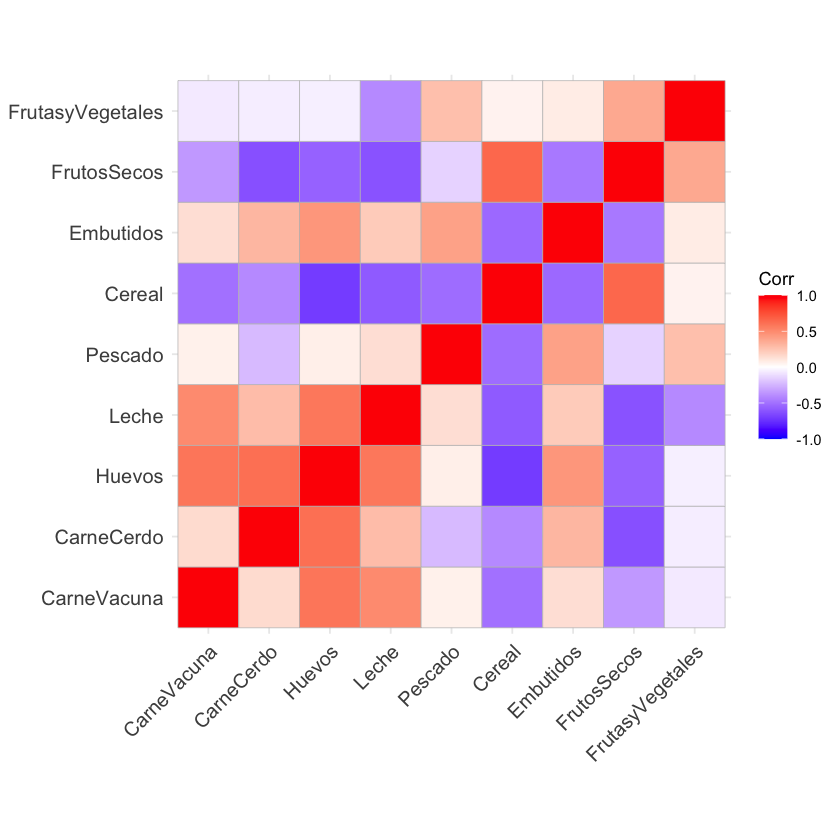

In [10]:
# muestra solo la mitad un rectangulo que repite valores en espejo
ggcorrplot(corr_matrix)

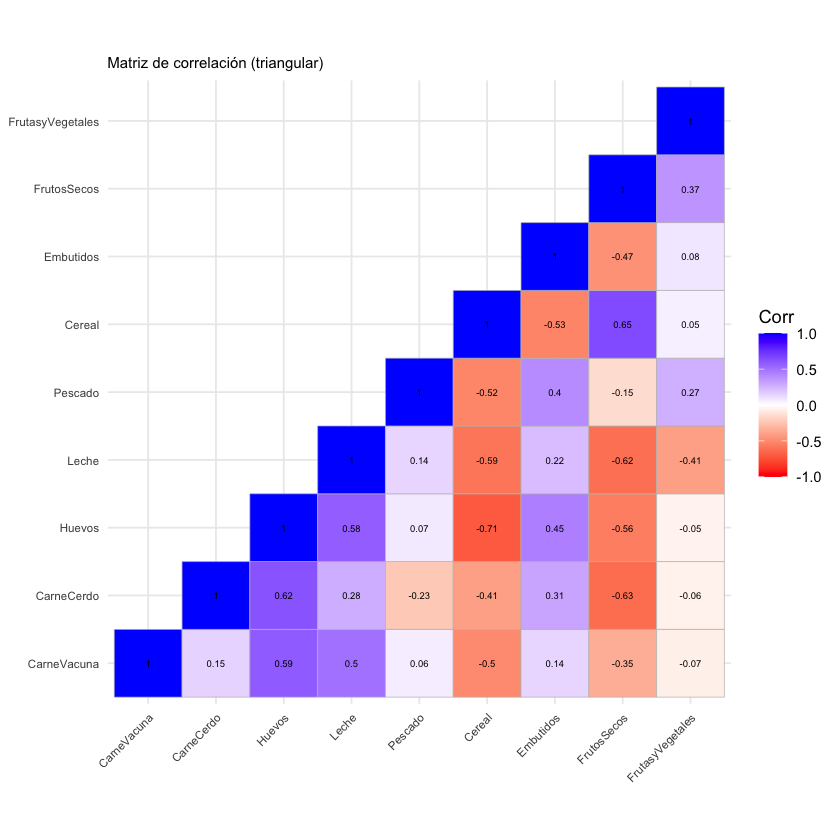

In [20]:
ggcorrplot(corr_matrix,
           method = "square",
           type = "lower",      # muestra solo la mitad inferior, "upper" para superior
           lab = TRUE,          # muestra los valores numéricos
           lab_size = 2,
           colors = c("red", "white", "blue"),
           show.diag = TRUE,
           title = "Matriz de correlación (triangular)") +
  theme(
    axis.text.x = element_text(size = 7),     # tamaño de texto en eje X
    axis.text.y = element_text(size = 7),     # tamaño de texto en eje Y
    plot.title = element_text(size = 9)      # tamaño del título
  )

In [21]:
# Apply PCA
pca <- PCA(X, 
           scale.unit = TRUE,   # Estandariza las variables (media 0, varianza 1)
           ncp=2,
           graph = TRUE,        # Muestra el gráfico automáticamente
           ind.sup = NULL)      # No hay individuos suplementarios

In [22]:
summary(pca)


Call:
PCA(X = X, scale.unit = TRUE, ncp = 2, ind.sup = NULL, graph = TRUE) 


Eigenvalues
                       Dim.1   Dim.2   Dim.3   Dim.4   Dim.5   Dim.6   Dim.7
Variance               4.006   1.635   1.128   0.955   0.464   0.325   0.272
% of var.             44.516  18.167  12.532  10.607   5.154   3.613   3.018
Cumulative % of var.  44.516  62.683  75.215  85.822  90.976  94.589  97.607
                       Dim.8   Dim.9
Variance               0.116   0.099
% of var.              1.292   1.101
Cumulative % of var.  98.899 100.000

Individuals (the 10 first)
                     Dist    Dim.1    ctr   cos2    Dim.2    ctr   cos2  
1                |  4.547 | -3.557 12.634  0.612 | -1.664  6.775  0.134 |
2                |  2.498 |  1.452  2.105  0.338 | -1.063  2.763  0.181 |
3                |  1.966 |  1.655  2.736  0.709 |  0.163  0.065  0.007 |
4                |  3.717 | -3.199 10.215  0.741 | -1.328  4.314  0.128 |
5                |  1.771 |  0.378  0.143  0.046 | -0.6

* **Dist**: distancia del individuo al centro de masa
* **ctr**: es el cos2/autovalor * 100. Cuanto está explicado de la varianza
* **cos2**: cuadrado de la dimensión. Contribución de los ejes a la variable
* **comunalidad** suma de las contribuciones al cuadrado

In [23]:
# Eigenvalores (varianza explicada)
pca$eig

,eigenvalue,percentage of variance,cumulative percentage of variance
comp 1,4.0064376,44.515973,44.51597
comp 2,1.6349994,18.166661,62.68263
comp 3,1.1279195,12.532439,75.21507
comp 4,0.9546640,10.607377,85.82245
comp 5,0.4638384,5.153760,90.97621
comp 6,0.3251310,3.612566,94.58878
comp 7,0.2716063,3.017848,97.60662
comp 8,0.1162919,1.292132,98.89876
comp 9,0.0991119,1.101243,100.00000


In [24]:
# Coordenadas de las variables
pca$var$coord

,Dim.1,Dim.2
CarneVacuna,0.6057056,-0.07192736
CarneCerdo,0.6216121,-0.30285749
Huevos,0.8540434,-0.04518280
Leche,0.7560622,-0.23602830
Pescado,0.2715180,0.82706958
Cereal,-0.8761911,-0.29855059
Embutidos,0.5949735,0.45114790
FrutosSecos,-0.8413450,0.18324705
FrutasyVegetales,-0.2210174,0.68561064


In [25]:
# Coordenadas de los individuos (observaciones-> paises en este caso)
pca$ind$coord

,Dim.1,Dim.2
1,-3.5572381,-1.66410153
2,1.4520059,-1.06270224
3,1.6554798,0.16278449
4,-3.1987084,-1.32789455
5,0.3781039,-0.61509588
6,2.4140424,0.29133192
7,1.4515379,0.45958638
8,1.5961042,-0.60829255
9,1.5186657,0.80155997
10,-2.2858842,1.02170143


In [26]:
# Contribución de cada variable a los componentes->ver las mas altas
pca$var$contrib

,Dim.1,Dim.2
CarneVacuna,9.157244,0.3164249
CarneCerdo,9.644517,5.6099503
Huevos,18.205455,0.1248616
Leche,14.267790,3.4073013
Pescado,1.840089,41.8375731
Cereal,19.161931,5.4515283
Embutidos,8.835618,12.4485929
FrutosSecos,17.668101,2.0537917
FrutasyVegetales,1.219255,28.7499760


In [27]:
# Calidad de representación (coseno cuadrado o comunalidad)
pca$var$cos2

,Dim.1,Dim.2
CarneVacuna,0.36687927,0.005173545
CarneCerdo,0.38640155,0.091722657
Huevos,0.72939019,0.002041486
Leche,0.57163009,0.055709357
Pescado,0.07372203,0.684044088
Cereal,0.76771081,0.089132457
Embutidos,0.35399350,0.203534426
FrutosSecos,0.70786143,0.033579483
FrutasyVegetales,0.04884870,0.470061949


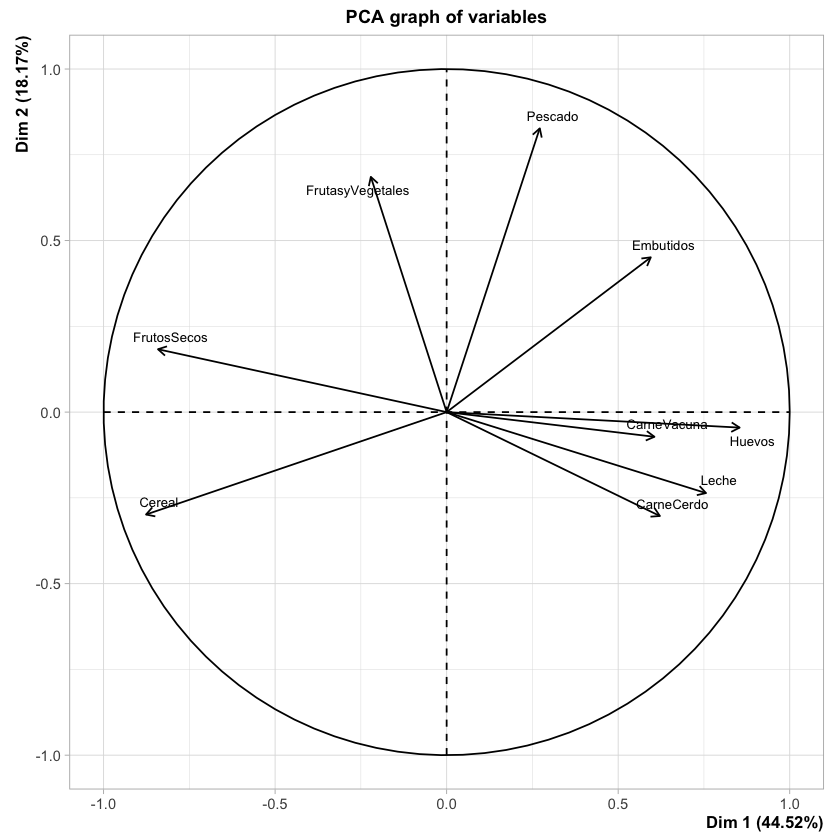

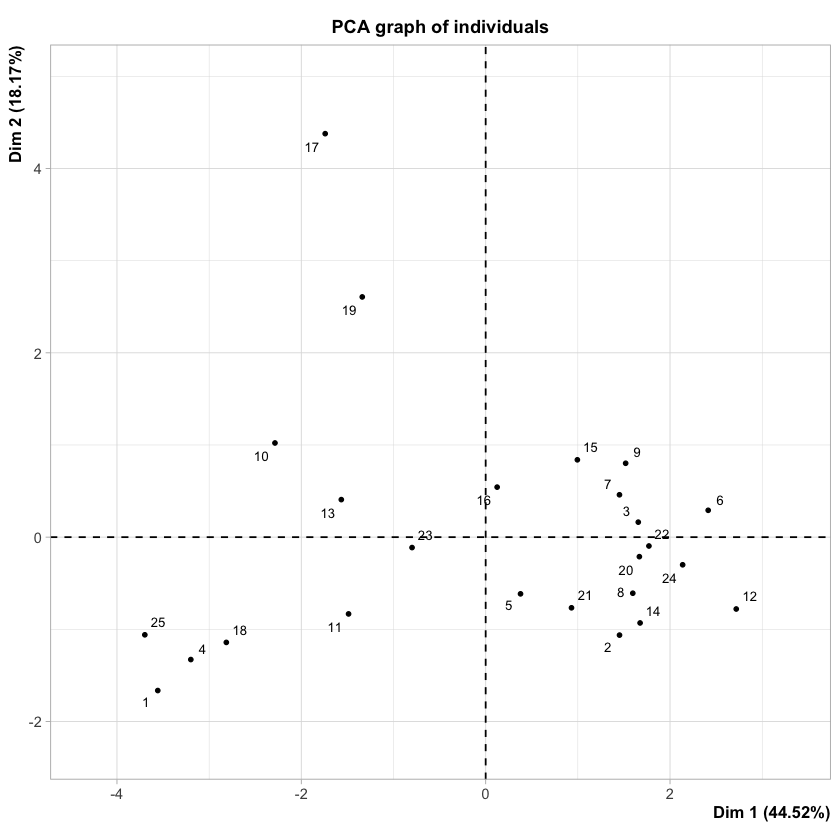

In [28]:
plot(pca, choix = "var", axes = c(1, 2), cex = 0.7)  # reduce el tamaño de texto
plot(pca, 
     choix = "ind",       # "ind" indica que querés graficar los individuos
     axes = c(1, 2),      # selecciona las dos primeras componentes
     cex = 0.7)           # reduce el tamaño de las etiquetas